# Fase 2 — Auditoría estructural (KDD)
### Segmentación de caries dentales con SAM 2: auditoría, partición y exportación del corpus

**Versión del notebook: ORIGINAL (rutas reales).**

Este notebook implementa la **Fase 2 (Preprocesamiento / auditoría estructural)** descrita en la Sección 3.3.2 del artículo. Parte de las **1069 imágenes** que deja la Fase 1 (`KDD-Fase 1.ipynb`), las audita, descarta 30 con defectos geométricos residuales (**1039 imágenes, 3606 lesiones**) y construye la partición 70/15/15 (**Tabla 2**).

| Sección | Contenido | Artículo |
| --- | --- | --- |
| 3 – 4 | Auditoría de resolución y fotométrica | 3.3.2 |
| 5 | Confirmación del esquema unificado | 3.3.2 |
| 6 | Verificación geométrica, descarte y figura del defecto | 3.3.2 |
| 7 – 8 | Verificación semántica y metadatos | 3.3.2 |
| 9 | Partición 70/15/15 y Tabla 2 | Tabla 2 |
| 10 | Exportación del corpus y `data.yaml` | 3.3.2 |
| 11 – 12 | Resumen final y paquete de entregables | — |

**Esta fase no modifica los píxeles de ninguna imagen.** Su producto es un corpus auditado y particionado que alimenta la Fase 3 (Transformación).

**Archivos que deja en Drive** (carpeta `Fase 2`): `Corpus/` (imágenes, etiquetas YOLO, `data.yaml`, `corpus_metadata.csv`), `final_corpus_summary.json`, `figuras/` y `Fase2_entregables.zip`.

## 2. Configuración del entorno y carga del estado de la Fase 1

In [17]:
!pip install -q imagehash rarfile pyyaml
# unrar binario requerido por rarfile si alguna fuente se distribuye como .rar
!apt-get install -qq unrar 2>/dev/null || echo

In [18]:
from google.colab import drive

drive.mount("/content/drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [19]:
import json
import math
import random
import shutil
import zipfile
from collections import defaultdict

import cv2
import numpy as np
import pandas as pd
import yaml
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.lines import Line2D
from PIL import Image
from tqdm.notebook import tqdm

In [ ]:
import os
from pathlib import Path
from dataclasses import dataclass
from typing import Optional, Literal, Any

DatasetSource = Literal["dentalai", "roboflow"]

DRIVE = Path("/content/drive/MyDrive")

# Salida de esta ejecución (carpetas "Fase 1" y "Fase 2")
OUTPUT_ROOT = DRIVE / "KDD_Caries"

# Origen de información previa (opcional)
LEGACY_ROOT = DRIVE / "KDD_Caries" / "previo"

# # Archivos comprimidos originales de cada fuente (solo se usan si hay que restaurar imágenes)
DENTALAI_ARCHIVE_CANDIDATES = [DRIVE / "KDD_Caries" / "datasets_raw" / "Dentalai-Dataset.tar"]
ROBOFLOW_ARCHIVE_CANDIDATES = [DRIVE / "KDD_Caries" / "datasets_raw" / "Dental-Caries-Roboflow.zip"]


def rel(path) -> str:
     """Ruta legible sin la raíz del Drive (se usa en todos los mensajes impresos)."""
     path = Path(path)
     for root, prefix in ((OUTPUT_ROOT, ""), (LEGACY_ROOT, "previo/")):
         try:
             return prefix + str(path.relative_to(root))
         except ValueError:
             continue
     return path.name


def locate_archive(candidates, patterns):
     """Devuelve el primer archivo existente de `candidates`; si no, busca `patterns`
     dentro de LEGACY_ROOT y de OUTPUT_ROOT."""
     for candidate in candidates:
         if Path(candidate).is_file():
             return Path(candidate)
     for root in (LEGACY_ROOT, OUTPUT_ROOT):
         if root.is_dir():
             for pattern in patterns:
                 hits = sorted(root.rglob(pattern))
                 if hits:
                     return hits[0]
     raise FileNotFoundError(f"No se encontró el archivo comprimido. Rutas probadas: {candidates}")


@dataclass(frozen=True)
class PipelineConfig:
     """Configuración centralizada de rutas y parámetros de la Fase 2."""

     phase1_dir: Path = OUTPUT_ROOT / "Fase 1"
     legacy_phase1_dir: Path = LEGACY_ROOT / "Fase 1"

     phase_dir: Path = OUTPUT_ROOT / "Fase 2"
     figures_dir: Path = OUTPUT_ROOT / "Fase 2" / "figuras"
     corpus_export_dir: Path = OUTPUT_ROOT / "Fase 2" / "Corpus"

     # Directorios temporales de Colab (deben coincidir con los de la Fase 1)
     extract_base: Path = Path("/content/datasets/extracted")
     interim_dir: Path = Path("/content/datasets/interim")

     split_ratios: tuple = (0.70, 0.15, 0.15)
     split_seed: int = 42


CONFIG = PipelineConfig()

for path in (CONFIG.phase_dir, CONFIG.figures_dir, CONFIG.corpus_export_dir, CONFIG.extract_base, CONFIG.interim_dir):
     path.mkdir(parents=True, exist_ok=True)

print(f"Salida Fase 2 : {rel(CONFIG.phase_dir)}")
print(f"Corpus final  : {rel(CONFIG.corpus_export_dir)}")

Salida Fase 2 : /content/drive/MyDrive/10mo Semestre/Titulacion II/KDD/Fase 2
Corpus final  : /content/drive/MyDrive/10mo Semestre/Titulacion II/KDD/Fase 2/Corpus


In [22]:
@dataclass
class SampleRecord:
    """Registro que acompaña a cada muestra durante todo el pipeline."""

    sample_id: str
    source: DatasetSource
    original_filename: str
    image_path: Path
    yolo_annotations: list  # lista de (class_id, [x1, y1, x2, y2, ...]) normalizados
    width: Optional[int] = None
    height: Optional[int] = None
    status: str = "pending"
    rejection_reason: Optional[str] = None

    @property
    def num_masks(self) -> int:
        return len(self.yolo_annotations)


def build_sample_id(source: DatasetSource, filename: str) -> str:
    import hashlib
    digest = hashlib.sha1(filename.encode("utf-8")).hexdigest()[:10]
    return f"{source}_{digest}"

Se carga el estado guardado por la Fase 1 y se comprueba que las imágenes sigan en disco; si la sesión es nueva, se vuelven a extraer los archivos originales.

In [23]:
def find_state_file() -> Path:
    for base in (CONFIG.phase1_dir, CONFIG.legacy_phase1_dir):
        candidate = base / "phase1_state.json"
        if candidate.is_file():
            return candidate
    raise FileNotFoundError("No se encontró phase1_state.json. Ejecute primero el notebook de la Fase 1.")


STATE_PATH = find_state_file()
with open(STATE_PATH, "r", encoding="utf-8") as handle:
    phase1_state = json.load(handle)

all_records = [
    SampleRecord(
        sample_id=d["sample_id"], source=d["source"], original_filename=d["original_filename"],
        image_path=Path(d["image_path"]),
        yolo_annotations=[(int(c), list(coords)) for c, coords in d["yolo_annotations"]],
        width=d["width"], height=d["height"], status=d["status"], rejection_reason=d["rejection_reason"],
    )
    for d in phase1_state["records"]
]
initial_counts = phase1_state["initial_counts"]
duplicate_log = phase1_state["duplicate_log"]

final_included = [r for r in all_records if r.status == "included"]
print(f"Estado cargado desde: {STATE_PATH}")
print(f"Registros: {len(all_records)} | corpus heredado de la Fase 1: {len(final_included)}")

Estado cargado desde: /content/drive/MyDrive/10mo Semestre/Titulacion II/KDD/Fase 1/phase1_state.json
Registros: 2154 | corpus heredado de la Fase 1: 1069


In [24]:
import zipfile
import tarfile
import shutil

try:
    import rarfile
    RARFILE_AVAILABLE = True
except ImportError:
    RARFILE_AVAILABLE = False


def _is_already_extracted(dest_dir: Path) -> bool:
    return dest_dir.is_dir() and any(dest_dir.iterdir())


def extract_dataset(archive_path: Path, dest_dir: Path, label: str) -> Path:
    """Extrae un archivo .zip, .rar o .tar en dest_dir, detectando el formato
    a partir de la extensión real del archivo. Omite la extracción si el
    directorio destino ya contiene contenido.
    """
    if not archive_path.is_file():
        raise FileNotFoundError(f"No se encontró el archivo comprimido de {label}: {archive_path}")

    if _is_already_extracted(dest_dir):
        print(f"[{label}] Ya extraído en: {dest_dir} — se omite.")
        return dest_dir

    dest_dir.mkdir(parents=True, exist_ok=True)
    extension = archive_path.suffix.lower()

    try:
        if extension == ".zip":
            with zipfile.ZipFile(archive_path) as archive:
                bad_file = archive.testzip()
                if bad_file is not None:
                    raise zipfile.BadZipFile(f"Archivo corrupto dentro del zip: {bad_file}")
                archive.extractall(dest_dir)

        elif extension == ".tar":
            with tarfile.open(archive_path, "r") as archive:
                archive.extractall(dest_dir)

        elif extension == ".rar":
            if not RARFILE_AVAILABLE:
                raise RuntimeError("rarfile no está disponible para extraer archivos .rar.")
            with rarfile.RarFile(archive_path) as archive:
                archive.extractall(dest_dir)

        else:
            raise ValueError(f"Formato de archivo no soportado para {label}: {extension}")

    except Exception as error:
        shutil.rmtree(dest_dir, ignore_errors=True)
        raise RuntimeError(f"Error extrayendo {archive_path}: {error}") from error

    print(f"[{label}] Extraído ({extension}) -> {dest_dir}")
    return dest_dir


missing = [r for r in final_included if not r.image_path.exists()]
if missing:
    print(f"Faltan {len(missing)} imágenes en disco; se vuelven a extraer los archivos originales.")
    DENTALAI_DIR = extract_dataset(
        locate_archive(DENTALAI_ARCHIVE_CANDIDATES, ["*entalai*.tar", "*entalAI*.tar"]),
        CONFIG.extract_base / "dentalai", "DentalAI")
    ROBOFLOW_DIR = extract_dataset(
        locate_archive(ROBOFLOW_ARCHIVE_CANDIDATES, ["*oboflow*.zip", "*aries*.zip"]),
        CONFIG.extract_base / "roboflow", "Roboflow")

    # Las imágenes convertidas a RGB en la Fase 1 viven en interim_dir: se regeneran desde el original.
    still_missing = [r for r in final_included if not r.image_path.exists()]
    if still_missing:
        by_name = {}
        for source, base in (("dentalai", DENTALAI_DIR), ("roboflow", ROBOFLOW_DIR)):
            for p in base.rglob("*"):
                if p.is_file() and p.suffix.lower() in (".jpg", ".jpeg", ".png", ".bmp", ".tiff"):
                    by_name.setdefault((source, p.name), p)
        for record in still_missing:
            origin = by_name.get((record.source, record.original_filename))
            if origin is None:
                raise FileNotFoundError(f"No se pudo restaurar {record.sample_id} ({record.original_filename}).")
            record.image_path.parent.mkdir(parents=True, exist_ok=True)
            with Image.open(origin) as img:
                img.convert("RGB").save(record.image_path, quality=95)
        print(f"Regeneradas {len(still_missing)} imágenes convertidas a RGB.")

assert all(r.image_path.exists() for r in final_included), "Aún faltan imágenes del corpus."
print("Todas las imágenes del corpus están disponibles en disco.")

Todas las imágenes del corpus están disponibles en disco.


# FASE 2 — Auditoría estructural
## 3. Auditoría de resolución

DentalAI conserva las resoluciones de captura originales (anchos de 640 a 8688 px); Roboflow ingresa normalizado a 640×640 px.

In [25]:
def audit_resolution(records: list[SampleRecord]) -> pd.DataFrame:
    df = pd.DataFrame([{"source": r.source, "width": r.width, "height": r.height} for r in records])
    df["area"] = df["width"] * df["height"]
    return df


resolution_df = audit_resolution(final_included)
resolution_df.groupby("source").agg(
    ancho_min=("width", "min"), ancho_max=("width", "max"), ancho_promedio=("width", "mean"),
    alto_min=("height", "min"), alto_max=("height", "max"), alto_promedio=("height", "mean"),
).round(2)

,ancho_min,ancho_max,ancho_promedio,alto_min,alto_max,alto_promedio
source,,,,,,
dentalai,640,8688,3569.73,480,6000,2477.54
roboflow,640,640,640.00,640,640,640.00


## 4. Auditoría fotométrica

Media y desviación por canal, por fuente. La diferencia sistemática en el canal azul (114,61 en DentalAI frente a 106,01 en Roboflow) indica que las fuentes no comparten iluminante de captura.

In [26]:
def compute_photometric_stats(image_path: Path) -> dict[str, float]:
    image = cv2.imread(str(image_path), cv2.IMREAD_COLOR)
    means, stds = image.mean(axis=(0, 1)), image.std(axis=(0, 1))
    return {
        "mean_b": float(means[0]), "mean_g": float(means[1]), "mean_r": float(means[2]),
        "std_b": float(stds[0]), "std_g": float(stds[1]), "std_r": float(stds[2]),
    }


photometric_rows = []
for record in tqdm(final_included, desc="Auditoría fotométrica"):
    stats = compute_photometric_stats(record.image_path)
    stats.update({"sample_id": record.sample_id, "source": record.source})
    photometric_rows.append(stats)

photometric_df = pd.DataFrame(photometric_rows)
photometric_df.groupby("source")[["mean_r", "mean_g", "mean_b", "std_r", "std_g", "std_b"]].mean().round(2)

Auditoría fotométrica:   0%|          | 0/1069 [00:00<?, ?it/s]

,mean_r,mean_g,mean_b,std_r,std_g,std_b
source,,,,,,
dentalai,168.97,123.42,114.61,47.65,50.63,49.07
roboflow,160.31,117.86,106.01,41.31,46.56,44.25


## 5. Confirmación del esquema de anotación unificado

Todas las muestras deben tener anotaciones YOLO válidas y clase única `0` (`Caries`).

In [27]:
def confirm_unified_schema(records: list[SampleRecord]) -> pd.DataFrame:
    rows = []
    for record in records:
        class_ids = {class_id for class_id, _ in record.yolo_annotations}
        rows.append({
            "sample_id": record.sample_id,
            "source": record.source,
            "esquema_yolo_ok": len(record.yolo_annotations) > 0,
            "clase_unica_ok": class_ids == {0},
        })
    return pd.DataFrame(rows)


schema_confirmation_df = confirm_unified_schema(final_included)
schema_confirmation_df[["esquema_yolo_ok", "clase_unica_ok"]].all()

,0
esquema_yolo_ok,True
clase_unica_ok,True


## 6. Verificación geométrica

Segunda pasada, más estricta que la de la Fase 1: busca polígonos abiertos, vértices repetidos y coordenadas fuera de [0, 1].

In [28]:
def verify_geometry(record: SampleRecord) -> list[str]:
    issues = []
    if len(record.yolo_annotations) == 0:
        return ["mascara_vacia"]

    for _, coords in record.yolo_annotations:
        points = [(coords[i], coords[i + 1]) for i in range(0, len(coords), 2)]
        if len(points) < 3:
            issues.append("poligono_abierto")
            continue
        deduplicated = [p for i, p in enumerate(points) if i == 0 or p != points[i - 1]]
        if len(deduplicated) != len(points):
            issues.append("vertices_repetidos")
        xs, ys = [p[0] for p in points], [p[1] for p in points]
        if min(xs) < 0 or min(ys) < 0 or max(xs) > 1.0 or max(ys) > 1.0:
            issues.append("coordenadas_fuera_de_rango")

    return issues


geometry_df = pd.DataFrame([
    {"sample_id": r.sample_id, "source": r.source, "num_issues": len(verify_geometry(r)),
     "issues": verify_geometry(r)}
    for r in final_included
])
geometry_df["num_issues"].value_counts()

,count
num_issues,
0,1039
1,24
2,4
5,1
3,1


### 6.1. Descarte de las muestras con defectos geométricos residuales

Se descartan 30 muestras, lo que reduce el corpus de 1069 a **1039 imágenes**. Desde aquí todo opera sobre el corpus depurado.

In [29]:
GEOMETRY_ISSUE_IDS = set(geometry_df.loc[geometry_df["num_issues"] > 0, "sample_id"])

geometry_rejection_log = []
for record in final_included:
    if record.sample_id in GEOMETRY_ISSUE_IDS and record.status == "included":
        record.status = "rejected"
        record.rejection_reason = "geometria_residual_invalida"
        geometry_rejection_log.append(record.sample_id)

# A partir de aquí, todas las secciones subsiguientes (13, 14, 15) deben
# operar sobre el corpus ya depurado de este defecto.
final_included = [r for r in final_included if r.status == "included"]

print(f"Muestras descartadas por defectos geométricos residuales: {len(geometry_rejection_log)}")
print(f"Corpus final tras la corrección de la Sección 12: {len(final_included)}")
print(f"  - DentalAI: {sum(1 for r in final_included if r.source == 'dentalai')}")
print(f"  - Roboflow: {sum(1 for r in final_included if r.source == 'roboflow')}")

Muestras descartadas por defectos geométricos residuales: 30
Corpus final tras la corrección de la Sección 12: 1039
  - DentalAI: 593
  - Roboflow: 446


### 6.2. Figura: por qué se descarta una muestra por geometría inválida

Se muestra el polígono con el vértice repetido resaltado y un zoom del polígono.

In [30]:
def plot_geometry_defect(record: SampleRecord, issues: list[str], save_path: Optional[Path] = None, zoom_factor: float = 0.05) -> None:
    """Dibuja los polígonos de una muestra descartada por geometría inválida,
    resaltando vértices fuera de rango [0,1] o degenerados y vértices repetidos.
    La función puede hacer zoom en un vértice repetido si se detecta.
    """
    img = cv2.cvtColor(cv2.imread(str(record.image_path)), cv2.COLOR_BGR2RGB)
    h, w = img.shape[:2]

    legend_elements = []
    repeated_vertex_coords = None # Para almacenar la posición del primer vértice repetido encontrado
    polygon_points_for_zoom = None # Para almacenar los puntos del polígono con el defecto

    for class_id, coords in record.yolo_annotations:
        points = [(coords[i] * w, coords[i + 1] * h) for i in range(0, len(coords), 2)]

        # Check for repeated vertices and store for potential zoom
        if "vertices_repetidos" in issues:
            # Check for consecutive identical points (in pixel coordinates)
            for i in range(len(points) - 1):
                if points[i] == points[i+1]:
                    if repeated_vertex_coords is None: # Almacenar solo el primer vértice repetido encontrado
                        repeated_vertex_coords = points[i+1]
                        polygon_points_for_zoom = points # Almacenar los puntos de este polígono
                    break # Solo necesitamos el primero para el zoom

    # Crear una sola figura con dos subplots si hay un polígono para hacer zoom
    if polygon_points_for_zoom and "vertices_repetidos" in issues:
        fig, (ax, ax2) = plt.subplots(1, 2, figsize=(12, 6)) # Aumentar el tamaño para dos subplots
    else:
        fig, ax = plt.subplots(figsize=(7, 7))
        ax2 = None # No hay segundo subplot

    # --- Plotear la imagen principal (primer subplot) ---
    ax.imshow(img)

    for class_id, coords in record.yolo_annotations:
        points = [(coords[i] * w, coords[i + 1] * h) for i in range(0, len(coords), 2)]

        # Plot the polygon outline
        xs = [p[0] for p in points] + [points[0][0]]
        ys = [p[1] for p in points] + [points[0][1]]
        ax.plot(xs, ys, "-", color="orange", linewidth=1.5)
        if not any(le.get_label() == "Polígono anotado" for le in legend_elements):
            legend_elements.append(mpatches.Patch(color="orange", label="Polígono anotado"))

        # Highlight out-of-range vertices
        if "coordenadas_fuera_de_rango" in issues:
            for i in range(0, len(coords), 2):
                x_norm, y_norm = coords[i], coords[i + 1]
                if x_norm < 0 or x_norm > 1.0 or y_norm < 0 or y_norm > 1.0:
                    ax.plot(x_norm * w, y_norm * h, "o", color="red", markersize=10)
                    if not any(le.get_label() == "Vértice fuera de rango" for le in legend_elements):
                        legend_elements.append(Line2D([0], [0], marker='o', color='w', label='Vértice fuera de rango',
                                                      markerfacecolor='red', markersize=10))

        # Highlight repeated vertices in main plot
        if "vertices_repetidos" in issues:
            for i in range(len(points) - 1):
                if points[i] == points[i+1]:
                    ax.plot(points[i+1][0], points[i+1][1], 's', color='blue', markersize=12,
                             markerfacecolor='none', markeredgewidth=2)
                    if not any(le.get_label() == "Vértice repetido" for le in legend_elements):
                        legend_elements.append(Line2D([0], [0], marker='s', color='w', label='Vértice repetido',
                                                      markerfacecolor='none', markeredgecolor='blue', markersize=12, markeredgewidth=2))

    ax.set_title(
        f"sample_id={record.sample_id} — motivo de descarte: {', '.join(issues)}",
        fontsize=10, color="firebrick",
    )
    ax.axis("off")
    ax.legend(handles=legend_elements, loc="lower right", fontsize=8)

    # Aplicar zoom si se encontró un vértice repetido (en el subplot principal)
    if repeated_vertex_coords and "vertices_repetidos" in issues and ax2 is None: # Solo si no hay segundo subplot
        center_x, center_y = repeated_vertex_coords
        # Calcular límites del zoom
        half_width = w * zoom_factor / 2
        half_height = h * zoom_factor / 2
        ax.set_xlim(max(0, center_x - half_width), min(w, center_x + half_width))
        ax.set_ylim(max(0, center_y - half_height), min(h, center_y + half_height))

    # --- Generar el segundo subplot con solo el polígono y zoom (si aplica) ---
    if ax2 is not None and polygon_points_for_zoom and "vertices_repetidos" in issues:
        xs_zoom = [p[0] for p in polygon_points_for_zoom] + [polygon_points_for_zoom[0][0]]
        ys_zoom = [p[1] for p in polygon_points_for_zoom] + [polygon_points_for_zoom[0][1]]

        ax2.plot(xs_zoom, ys_zoom, "-o", color="orange")

        # Resaltar el vértice repetido también en esta figura
        if repeated_vertex_coords:
            ax2.plot(repeated_vertex_coords[0], repeated_vertex_coords[1], 's', color='blue', markersize=12,
                     markerfacecolor='none', markeredgewidth=2)

        # Numerar los vértices
        for idx, (x, y) in enumerate(polygon_points_for_zoom):
            ax2.text(x, y, str(idx), color='black', fontsize=8, ha='center', va='bottom')

        ax2.set_aspect("equal")
        ax2.invert_yaxis() # YOLO coordinates typically have origin at top-left

        # Ajustar los límites del eje para centrar en el polígono
        all_x = [p[0] for p in polygon_points_for_zoom]
        all_y = [p[1] for p in polygon_points_for_zoom]
        margin = (max(all_x) - min(all_x)) * 0.1 # Añadir un 10% de margen
        ax2.set_xlim(min(all_x) - margin, max(all_x) + margin)
        ax2.set_ylim(max(all_y) + margin, min(all_y) - margin) # Invertido por invert_yaxis

        ax2.set_title(f"Zoom del Polígono con 'vertices_repetidos'\n(sample_id={record.sample_id})", fontsize=10)
        # ax2.axis("off") # Se puede habilitar si se quiere quitar los ejes numéricos

    plt.tight_layout()
    if save_path:
        # Guardar la figura combinada
        plt.savefig(save_path, dpi=150, bbox_inches="tight")
    plt.show()

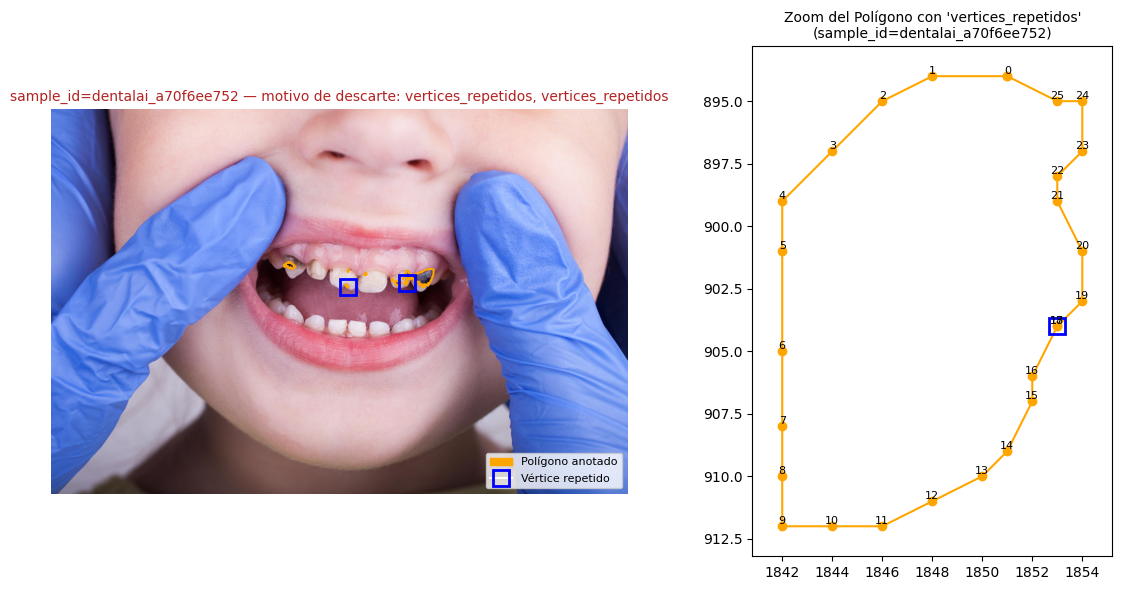

In [31]:
# Get all sample_ids that have geometry issues
geometry_issue_sample_ids = geometry_df.loc[geometry_df["num_issues"] > 0, "sample_id"].tolist()

# Filter for samples that specifically have 'vertices_repetidos' issue
# to ensure the dual-plot functionality is triggered
repeated_vertices_sample_ids = []
for sample_id in geometry_issue_sample_ids:
    issues = geometry_df.loc[geometry_df["sample_id"] == sample_id, "issues"].iloc[0]
    if "vertices_repetidos" in issues:
        repeated_vertices_sample_ids.append(sample_id)

random.seed(42)  # solo fija el ejemplo ilustrativo de la figura
if repeated_vertices_sample_ids:
    # Randomly select one sample_id from the filtered list
    random_example_id = random.choice(repeated_vertices_sample_ids)

    example_record = next(r for r in all_records if r.sample_id == random_example_id)
    example_issues = geometry_df.loc[geometry_df["sample_id"] == random_example_id, "issues"].iloc[0]

    plot_geometry_defect(
        example_record, example_issues,
        save_path=CONFIG.figures_dir / "figura_defecto_geometrico_side_by_side.png",
    )
else:
    print("No se encontraron muestras descartadas por defectos geométricos con 'vertices repetidos' para visualizar.")

## 7. Verificación semántica

Coherencia de clases (solo la clase `0`) y consistencia del número de máscaras.

In [32]:
def verify_semantics(records: list[SampleRecord]) -> pd.DataFrame:
    rows = []
    for record in records:
        class_ids = {class_id for class_id, _ in record.yolo_annotations}
        rows.append({
            "sample_id": record.sample_id,
            "coherencia_clases_ok": class_ids <= {0},
            "num_mascaras_consistente": record.num_masks == len(record.yolo_annotations),
        })
    return pd.DataFrame(rows)


semantic_df = verify_semantics(final_included)
semantic_df[["coherencia_clases_ok", "num_mascaras_consistente"]].all()

,0
coherencia_clases_ok,True
num_mascaras_consistente,True


## 8. Normalización de metadatos

Tabla común: identificador, fuente, nombre original, dimensiones, número de máscaras y clase.

In [33]:
def build_metadata_table(records: list[SampleRecord]) -> pd.DataFrame:
    return pd.DataFrame([{
        "sample_id": r.sample_id,
        "dataset_origen": r.source,
        "nombre_original": r.original_filename,
        "ancho": r.width,
        "alto": r.height,
        "num_mascaras": r.num_masks,
        "clase": "caries",
    } for r in records])


metadata_df = build_metadata_table(final_included)
metadata_df.head()

,sample_id,dataset_origen,nombre_original,ancho,alto,num_mascaras,clase
0,dentalai_cbc794c030,dentalai,1000_jpg.rf.ad94534c8a4bf33d828b910160011dd9.jpg,4577,3051,1,caries
1,dentalai_4fc4dca68d,dentalai,1008_jpg.rf.e756a25bd9b1eca086c9e49c5fbdf9f1.jpg,4896,3264,1,caries
2,dentalai_32e2b08c2d,dentalai,100_jpg.rf.b82625b276769d80f0c12c1f0b318d6f.jpg,5184,3456,9,caries
3,dentalai_c7f3f46429,dentalai,1018_jpg.rf.aabbf1107ffd09f3e6e0d1e7804d8eb9.jpg,2868,1912,2,caries
4,dentalai_4467f2ea64,dentalai,1020_jpg.rf.45bf4df271eb2b540fe792f3f8296a4f.jpg,3000,4016,6,caries


## 9. Partición experimental 70/15/15

Asignación determinística (semilla 42), estratificada por fuente (y por presencia de lesión; todas las muestras tienen al menos una). La partición se hace **por imagen**: todas las lesiones de una fotografía quedan en la misma partición. Esta partición se mantiene fija en las tres réplicas del experimento.

### 9.1. Asignación de particiones

In [34]:
def assign_splits(metadata: pd.DataFrame, split_ratios: tuple, seed: int) -> pd.DataFrame:
    """Asigna cada muestra a train/valid/test de forma estratificada por
    (dataset_origen, presencia_lesion), preservando las proporciones globales
    dentro de cada estrato mediante un muestreo aleatorio con semilla fija.
    """
    rng = random.Random(seed)
    train_ratio, val_ratio, _ = split_ratios

    strata = metadata.copy()
    strata["presencia_lesion"] = strata["num_mascaras"] > 0
    strata["estrato"] = (
        strata["dataset_origen"] + "_" +
        strata["presencia_lesion"].map({True: "con_lesion", False: "sin_lesion"})
    )

    assignments = {}
    for estrato, group in strata.groupby("estrato"):
        ids = group["sample_id"].tolist()
        rng.shuffle(ids)

        n = len(ids)
        n_train = round(n * train_ratio)
        n_val = round(n * val_ratio)
        n_val = min(n_val, n - n_train)  # evita que el redondeo exceda el total
        n_test = n - n_train - n_val

        for sid in ids[:n_train]:
            assignments[sid] = "train"
        for sid in ids[n_train:n_train + n_val]:
            assignments[sid] = "valid"
        for sid in ids[n_train + n_val:]:
            assignments[sid] = "test"

    strata["split"] = strata["sample_id"].map(assignments)
    return strata


metadata_df = assign_splits(metadata_df, CONFIG.split_ratios, CONFIG.split_seed)

split_summary = (
    metadata_df.groupby(["split", "dataset_origen"])
    .size()
    .rename("n_muestras")
    .reset_index()
)
split_summary

,split,dataset_origen,n_muestras
0,test,dentalai,89
1,test,roboflow,67
2,train,dentalai,415
3,train,roboflow,312
4,valid,dentalai,89
5,valid,roboflow,67


### 9.2. Tabla 2 del artículo: imágenes y lesiones por partición y fuente

Celda de solo agregación sobre `metadata_df`. Cada máscara anotada cuenta como una lesión; el total esperado es 3606 (2455 / 587 / 564).

In [35]:
from IPython.display import display


def build_table2(metadata: pd.DataFrame) -> pd.DataFrame:
    """Tabla 2 del artículo: imágenes y lesiones por partición y fuente.
    Celda de solo agregación; no modifica `metadata`. Cada máscara anotada es una lesión."""
    split_names = {"train": "Entrenamiento", "valid": "Validación", "test": "Prueba"}
    grouped = metadata.groupby(["split", "dataset_origen"]).agg(
        imagenes=("sample_id", "nunique"), lesiones=("num_mascaras", "sum")
    )
    rows = []
    for split, label in split_names.items():
        d, r = grouped.loc[(split, "dentalai")], grouped.loc[(split, "roboflow")]
        rows.append({
            "Partición": label,
            "DentalAI (imgs.)": int(d["imagenes"]), "Roboflow (imgs.)": int(r["imagenes"]),
            "Total imágenes": int(d["imagenes"] + r["imagenes"]),
            "DentalAI (les.)": int(d["lesiones"]), "Roboflow (les.)": int(r["lesiones"]),
            "Total lesiones": int(d["lesiones"] + r["lesiones"]),
        })
    table = pd.DataFrame(rows)
    total = table.drop(columns="Partición").sum().to_dict()
    total["Partición"] = "Total"
    return pd.concat([table, pd.DataFrame([total])], ignore_index=True)


table2 = build_table2(metadata_df)
display(table2)

# Verificación contra el artículo (Tabla 2): solo informa, no detiene la ejecución.
EXPECTED_TABLE2 = [
    ["Entrenamiento", 415, 312, 727, 1492, 963, 2455],
    ["Validación",     89,  67, 156,  347, 240,  587],
    ["Prueba",         89,  67, 156,  342, 222,  564],
    ["Total",         593, 446, 1039, 2181, 1425, 3606],
]
expected_df = pd.DataFrame(EXPECTED_TABLE2, columns=table2.columns)
if table2.astype(str).equals(expected_df.astype(str)):
    print("Tabla 2: coincide con el artículo (3606 lesiones = 2455 / 587 / 564).")
else:
    diff = (table2.set_index("Partición").astype(int) - expected_df.set_index("Partición").astype(int))
    print("AVISO: la Tabla 2 difiere del artículo. Diferencias (obtenido - esperado):")
    display(diff)

,Partición,DentalAI (imgs.),Roboflow (imgs.),Total imágenes,DentalAI (les.),Roboflow (les.),Total lesiones
0,Entrenamiento,415,312,727,1492,963,2455
1,Validación,89,67,156,347,240,587
2,Prueba,89,67,156,342,222,564
3,Total,593,446,1039,2181,1425,3606


Tabla 2: coincide con el artículo (3606 lesiones = 2455 / 587 / 564).


## 10. Exportación del corpus final

### 10.1. Imágenes y etiquetas YOLO por partición

In [36]:
import shutil


def write_yolo_label(label_path: Path, yolo_annotations: list) -> None:
    lines = []
    for class_id, coords in yolo_annotations:
        coords_str = " ".join(f"{c:.6f}" for c in coords)
        lines.append(f"{class_id} {coords_str}")
    label_path.write_text("\n".join(lines), encoding="utf-8")


def materialize_split_corpus(
    records: list[SampleRecord],
    metadata: pd.DataFrame,
    export_dir: Path,
) -> dict[str, int]:
    """Copia imágenes y escribe etiquetas YOLO en export_dir/<split>/images
    y export_dir/<split>/labels, para cada muestra de `records` según el
    split asignado en `metadata`.
    """
    split_by_id = dict(zip(metadata["sample_id"], metadata["split"]))
    written_counts = defaultdict(int)

    for split in ("train", "valid", "test"):
        (export_dir / split / "images").mkdir(parents=True, exist_ok=True)
        (export_dir / split / "labels").mkdir(parents=True, exist_ok=True)

    records_by_id = {r.sample_id: r for r in records}

    for sample_id, split in split_by_id.items():
        record = records_by_id.get(sample_id)
        if record is None:
            continue

        extension = record.image_path.suffix.lower() or ".jpg"
        dest_image = export_dir / split / "images" / f"{sample_id}{extension}"
        dest_label = export_dir / split / "labels" / f"{sample_id}.txt"

        shutil.copy2(record.image_path, dest_image)
        write_yolo_label(dest_label, record.yolo_annotations)
        written_counts[split] += 1

    return dict(written_counts)


materialized_counts = materialize_split_corpus(final_included, metadata_df, CONFIG.corpus_export_dir)
print("Muestras materializadas por split:", materialized_counts)

Muestras materializadas por split: {'valid': 156, 'train': 727, 'test': 156}


### 10.2. `data.yaml` y metadatos

In [37]:
data_yaml_content = {
    "path": str(CONFIG.corpus_export_dir),
    "train": "train/images",
    "val": "valid/images",
    "test": "test/images",
    "nc": 1,
    "names": ["Caries"],
}

with open(CONFIG.corpus_export_dir / "data.yaml", "w", encoding="utf-8") as handle:
    yaml.safe_dump(data_yaml_content, handle, sort_keys=False, allow_unicode=True)

# La tabla de metadatos (con el split asignado) se conserva junto al corpus.
metadata_df.to_csv(CONFIG.corpus_export_dir / "corpus_metadata.csv", index=False)

print(f"Corpus final exportado en: {CONFIG.corpus_export_dir}")
print(f"data.yaml escrito en    : {CONFIG.corpus_export_dir / 'data.yaml'}")

Corpus final exportado en: /content/drive/MyDrive/10mo Semestre/Titulacion II/KDD/Fase 2/Corpus
data.yaml escrito en    : /content/drive/MyDrive/10mo Semestre/Titulacion II/KDD/Fase 2/Corpus/data.yaml


In [38]:
# Metadatos del corpus con el split asignado, junto al corpus (trazabilidad)
metadata_df.to_csv(CONFIG.corpus_export_dir / "corpus_metadata.csv", index=False)
print(f"corpus_metadata.csv escrito en: {CONFIG.corpus_export_dir}")

corpus_metadata.csv escrito en: /content/drive/MyDrive/10mo Semestre/Titulacion II/KDD/Fase 2/Corpus


## 11. Resumen final del corpus

In [39]:
def build_final_summary(
    initial_counts, all_records, final_included, resolution_df, metadata_df, materialized_counts, export_dir
) -> dict:
    rejection_by_reason = defaultdict(int)
    for record in all_records:
        if record.status == "rejected":
            rejection_by_reason[record.rejection_reason or "desconocido"] += 1

    # Get the grouped data as a pandas Series
    grouped_split_source = metadata_df.groupby(["split", "dataset_origen"]).size()
    # Convert MultiIndex keys (tuples) to strings
    muestras_por_split_y_fuente_str_keys = {
        f"{k[0]}_{k[1]}": v for k, v in grouped_split_source.to_dict().items()
    }

    return {
        "total_inicial": initial_counts["total"],
        "total_inicial_por_fuente": {"dentalai": initial_counts["dentalai"], "roboflow": initial_counts["roboflow"]},
        "total_descartado_por_criterio": dict(rejection_by_reason),
        "total_aceptado_final": len(final_included),
        "aceptado_por_fuente": {
            source: sum(1 for r in final_included if r.source == source)
            for source in ("dentalai", "roboflow")
        },
        "resolucion_promedio": {
            "ancho": float(resolution_df["width"].mean()), "alto": float(resolution_df["height"].mean()),
        },
        "distribucion_mascaras": metadata_df["num_mascaras"].describe().to_dict(),
        "distribucion_por_clase": metadata_df["clase"].value_counts().to_dict(),
        "muestras_por_split": materialized_counts,
        "muestras_por_split_y_fuente": muestras_por_split_y_fuente_str_keys,
        "corpus_exportado_en": str(export_dir),
    }


final_summary = build_final_summary(
    initial_counts, all_records, final_included, resolution_df, metadata_df, materialized_counts, CONFIG.corpus_export_dir
)

with open(CONFIG.phase_dir / "final_corpus_summary.json", "w", encoding="utf-8") as handle:
    json.dump(final_summary, handle, indent=2, ensure_ascii=False)

final_summary

{'total_inicial': 2154,
 'total_inicial_por_fuente': {'dentalai': 1190, 'roboflow': 964},
 'total_descartado_por_criterio': {'desenfoque_severo': 71,
  'resolucion_insuficiente': 447,
  'geometria_residual_invalida': 30,
  'duplicado_perceptual': 564,
  'subexposicion_severa': 2,
  'sobreexposicion': 1},
 'total_aceptado_final': 1039,
 'aceptado_por_fuente': {'dentalai': 593, 'roboflow': 446},
 'resolucion_promedio': {'ancho': 2347.4087932647335,
  'alto': 1710.8971000935453},
 'distribucion_mascaras': {'count': 1039.0,
  'mean': 3.4706448508180943,
  'std': 2.8529899584869374,
  'min': 1.0,
  '25%': 1.0,
  '50%': 3.0,
  '75%': 5.0,
  'max': 22.0},
 'distribucion_por_clase': {'caries': 1039},
 'muestras_por_split': {'valid': 156, 'train': 727, 'test': 156},
 'muestras_por_split_y_fuente': {'test_dentalai': 89,
  'test_roboflow': 67,
  'train_dentalai': 415,
  'train_roboflow': 312,
  'valid_dentalai': 89,
  'valid_roboflow': 67},
 'corpus_exportado_en': '/content/drive/MyDrive/10mo Sem

Figura final: número de máscaras por imagen, distribución por fuente y por partición.

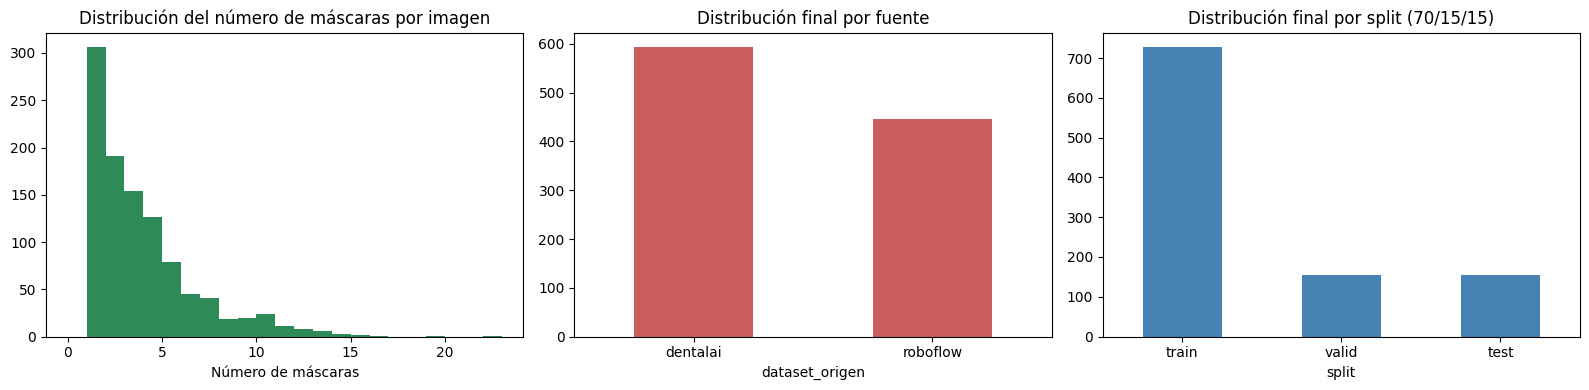

In [40]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

axes[0].hist(metadata_df["num_mascaras"], bins=range(0, metadata_df["num_mascaras"].max() + 2), color="seagreen")
axes[0].set_title("Distribución del número de máscaras por imagen")
axes[0].set_xlabel("Número de máscaras")

metadata_df["dataset_origen"].value_counts().plot(kind="bar", ax=axes[1], color="indianred")
axes[1].set_title("Distribución final por fuente")
axes[1].tick_params(axis="x", rotation=0)

metadata_df["split"].value_counts().reindex(["train", "valid", "test"]).plot(
    kind="bar", ax=axes[2], color="steelblue"
)
axes[2].set_title("Distribución final por split (70/15/15)")
axes[2].tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.savefig(CONFIG.figures_dir / "final_corpus_overview.png", dpi=150)
plt.show()

## 12. Paquete de entregables

Empaqueta los archivos livianos (metadatos, `data.yaml`, resumen y figuras) en un `.zip` dentro de `Fase 2`. Las imágenes del corpus quedan en `Corpus/` y no se incluyen en el paquete.

In [41]:
ZIP_PATH = CONFIG.phase_dir / "Fase2_entregables.zip"
light_files = [
    (CONFIG.corpus_export_dir / "corpus_metadata.csv", "corpus_metadata.csv"),
    (CONFIG.corpus_export_dir / "data.yaml", "data.yaml"),
    (CONFIG.phase_dir / "final_corpus_summary.json", "final_corpus_summary.json"),
] + [(p, f"figuras/{p.name}") for p in sorted(CONFIG.figures_dir.glob("*.png"))]

with zipfile.ZipFile(ZIP_PATH, "w", zipfile.ZIP_DEFLATED) as bundle:
    for path, arcname in light_files:
        bundle.write(path, arcname)

with zipfile.ZipFile(ZIP_PATH) as bundle:
    for name in bundle.namelist():
        print(" -", name)
print(f"\nPaquete generado: {ZIP_PATH}")

 - corpus_metadata.csv
 - data.yaml
 - final_corpus_summary.json
 - figuras/figura_defecto_geometrico_side_by_side.png
 - figuras/final_corpus_overview.png

Paquete generado: /content/drive/MyDrive/10mo Semestre/Titulacion II/KDD/Fase 2/Fase2_entregables.zip
